In [1]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('./weatherAUS.csv')

In [4]:
df.columns

Index(['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
       'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RainTomorrow'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

In [ ]:
df.isnull().sum()

,0
Date,0
Location,0
MinTemp,1485
MaxTemp,1261
Rainfall,3261
Evaporation,62790
Sunshine,69835
WindGustDir,10326
WindGustSpeed,10263
WindDir9am,10566


In [ ]:
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.000000,144199.000000,142199.000000,82670.000000,75625.000000,135197.000000,143693.000000,142398.000000,142806.000000,140953.000000,130395.00000,130432.000000,89572.000000,86102.000000,143693.000000,141851.00000
mean,12.194034,23.221348,2.360918,5.468232,7.611178,40.035230,14.043426,18.662657,68.880831,51.539116,1017.64994,1015.255889,4.447461,4.509930,16.990631,21.68339
std,6.398495,7.119049,8.478060,4.193704,3.785483,13.607062,8.915375,8.809800,19.029164,20.795902,7.10653,7.037414,2.887159,2.720357,6.488753,6.93665
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.50000,977.100000,0.000000,0.000000,-7.200000,-5.40000
25%,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.90000,1010.400000,1.000000,2.000000,12.300000,16.60000
50%,12.000000,22.600000,0.000000,4.800000,8.400000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.60000,1015.200000,5.000000,5.000000,16.700000,21.10000
75%,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.40000,1020.000000,7.000000,7.000000,21.600000,26.40000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.00000,1039.600000,9.000000,9.000000,40.200000,46.70000


In [ ]:
dias_cachondos = df[df['MaxTemp'] > 30]
display(dias_cachondos.head())

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No
8,2008-12-09,Albury,9.7,31.9,0.0,NaN,NaN,NNW,80.0,SE,...,42.0,9.0,1008.9,1003.6,NaN,NaN,18.3,30.2,No,Yes
9,2008-12-10,Albury,13.1,30.1,1.4,NaN,NaN,W,28.0,S,...,58.0,27.0,1007.0,1005.7,NaN,NaN,20.1,28.2,Yes,No
10,2008-12-11,Albury,13.4,30.4,0.0,NaN,NaN,N,30.0,SSE,...,48.0,22.0,1011.8,1008.7,NaN,NaN,20.4,28.8,No,Yes
21,2008-12-22,Albury,17.1,33.0,0.0,NaN,NaN,NE,43.0,NE,...,38.0,28.0,1013.6,1008.1,NaN,1.0,24.5,31.6,No,No


In [ ]:
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
maxima_temp_promedio_anio = df.groupby('Year')['MaxTemp'].mean()
print(maxima_temp_promedio_anio)

Year
2007    25.086885
2008    22.874359
2009    23.251019
2010    22.571247
2011    22.540180
2012    22.311424
2013    23.290936
2014    23.792739
2015    23.515652
2016    23.419984
2017    25.031702
Name: MaxTemp, dtype: float64


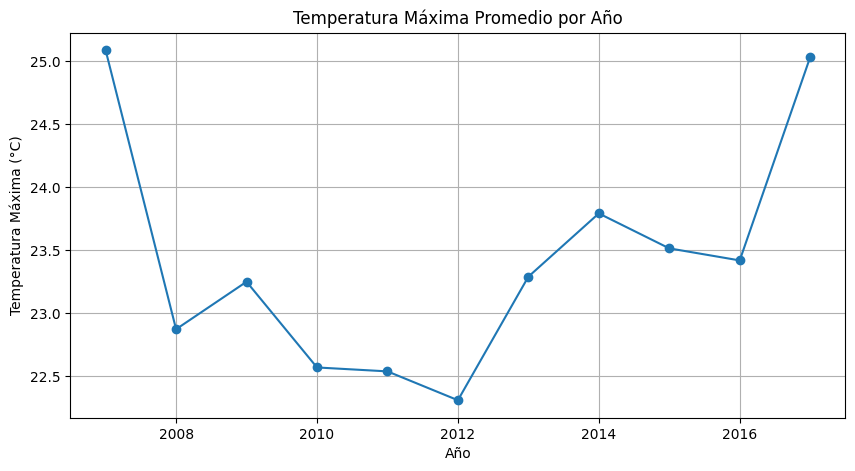

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,5))
maxima_temp_promedio_anio.plot(kind='line', marker='o')
plt.title('Temperatura Máxima Promedio por Año')
plt.xlabel('Año')
plt.ylabel('Temperatura Máxima (°C)')
plt.grid()
plt.show()


In [ ]:
correlation_matrix = df[['Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm']].corr()
print(correlation_matrix)

             Pressure9am  Pressure3pm   Temp9am   Temp3pm
Pressure9am     1.000000     0.961326 -0.422556 -0.286770
Pressure3pm     0.961326     1.000000 -0.470187 -0.389548
Temp9am        -0.422556    -0.470187  1.000000  0.860591
Temp3pm        -0.286770    -0.389548  0.860591  1.000000


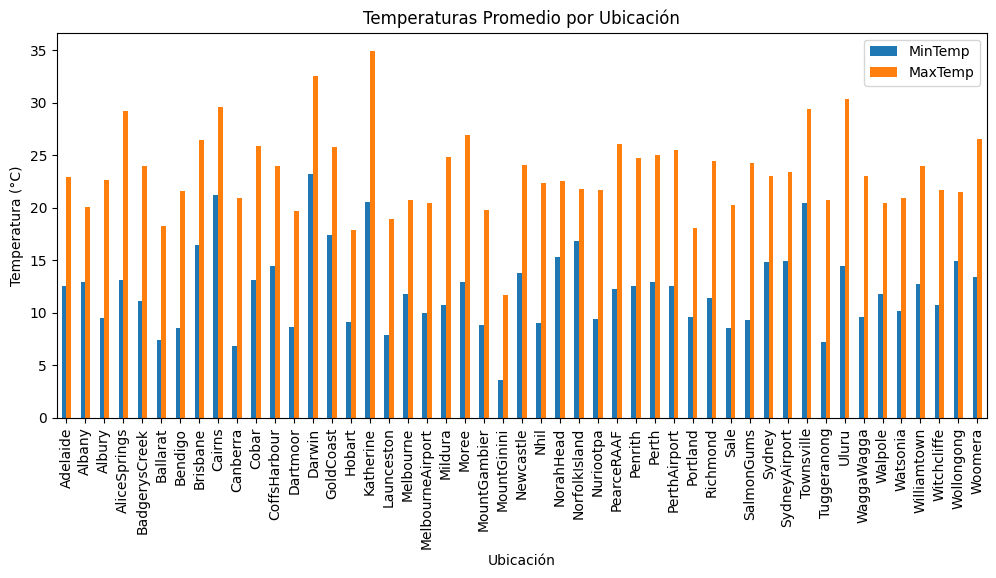

In [ ]:
location_temp_avg = df.groupby('Location')[['MinTemp', 'MaxTemp']].mean()
location_temp_avg.plot(kind='bar', figsize=(12,5))
plt.title('Temperaturas Promedio por Ubicación')
plt.xlabel('Ubicación')
plt.ylabel('Temperatura (°C)')
plt.show()

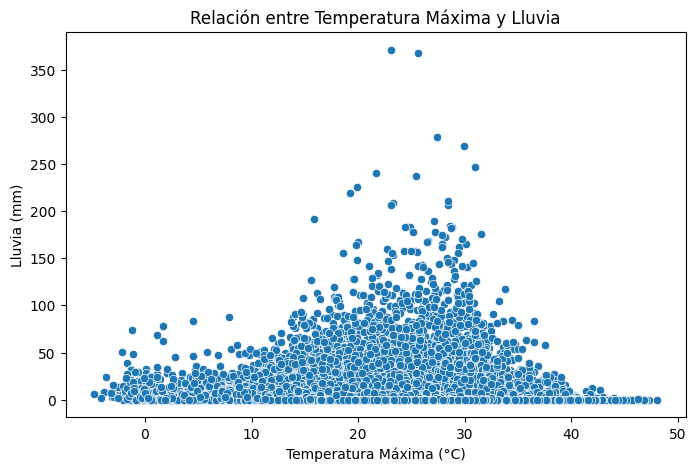

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(x=df['MaxTemp'], y=df['Rainfall'])
plt.title('Relación entre Temperatura Máxima y Lluvia')
plt.xlabel('Temperatura Máxima (°C)')
plt.ylabel('Lluvia (mm)')
plt.show()

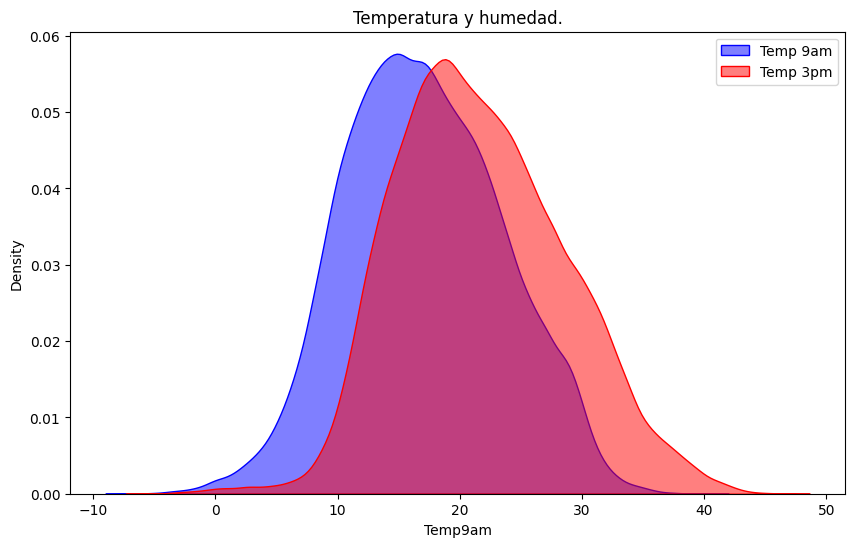

In [ ]:
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='Temp9am', label='Temp 9am', fill=True, color='blue', alpha=0.5)
sns.kdeplot(data=df, x='Temp3pm', label='Temp 3pm', fill=True, color='red', alpha=0.5)

plt.title('Temperatura y humedad.')
plt.legend()
plt.show()